# DQN (Deep Q Network) Notebook

In [8]:
import gym, warnings, os, torch, copy, random, gc
import torch.nn as nn
import numpy as np
import pandas as pd
from models import PolicyNet, SparsePolicyNet
from rl_utils.dqn import ReplayMemory, train
from  utils import (
    xavier_init_weights, 
    save_model_params, 
    plot_train_performance, 
    plot_result_dataframe,
    run_evaluation,
)
from typing import Union, Optional

warnings.filterwarnings("ignore")
os.environ["ENV_SEED"] = "3407"
torch.set_default_dtype(torch.float32)

In [9]:
SEED = int(os.environ["ENV_SEED"])
random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [10]:
#replay memory parameters
replay_memory_capacity = 10_000
batch_size = 32

#dense_optimizer hyperparameters
lr = 2.5e-5

#policy hyperparameters
gamma = 0.99
min_epsilon = 0.0
max_epsilon = 1.0
episodes = 2_000
target_network_update_step = 5
hidden_size = 128
results_dir = "sparsification_results"

train_env = gym.make("CartPole-v1")

#model hyper-parameters
observation_space = train_env.observation_space._shape[0]
action_space = train_env.action_space.n

replay_memory = ReplayMemory(replay_memory_capacity, observation_space)

sparsity_penalty_coefs = np.array([1e-05, 5e-5, 1e-4, 5e-4, 1e-3, 5e-3, 1e-2, 5e-2, 1e-1, 5e-1])

In [11]:
def run_train(
        policy_agent: Union[PolicyNet, SparsePolicyNet], 
        policy_target: Union[PolicyNet, SparsePolicyNet],
        policy_optimizer: torch.optim.Optimizer,
        policy_weights_filename: Optional[str]=None,
        save_best_weights: bool=True,
        sparse_penalty_coef: Optional[float]=None,
        plot_performance: bool=True,
    ):
    
    os.makedirs("params", exist_ok=True)
    train_env = gym.make("CartPole-v1")

    if isinstance(policy_agent, SparsePolicyNet):
        assert sparse_penalty_coef is not None

    if save_best_weights:
        assert policy_weights_filename is not None

    if isinstance(policy_agent, SparsePolicyNet) and sparse_penalty_coef is not None:
        lossfunc = lambda pred, target : nn.MSELoss()(pred[0], target) + ((sparse_penalty_coef * pred[1]) / batch_size)
    else:
        lossfunc = nn.MSELoss()
        
    try:
        train_performance, best_rewards = train(
            train_env,
            policy_agent,
            policy_target,
            replay_memory,
            lossfunc,
            policy_optimizer,
            episodes=episodes,
            batch_size=batch_size,
            gamma=gamma,
            min_epsilon=min_epsilon,
            max_epsilon=max_epsilon,
            max_episode_reward=train_env._max_episode_steps,
            continue_after_max_reward=False,
            target_network_update_step=target_network_update_step,
            weights_filename=policy_weights_filename,
            save_best_weights=save_best_weights,
            verbose=False,
            close_env=True,
        )
        replay_memory.clear()

    except KeyboardInterrupt:
        train_env.close()

    if plot_performance:
        plot_train_performance(train_performance, best_rewards)

    convergence_steps = len(train_performance["rewards"])
    return convergence_steps

## Train and Evaluate Dense Policy

 55%|█████▌    | 1101/2000 [02:31<02:03,  7.29it/s]


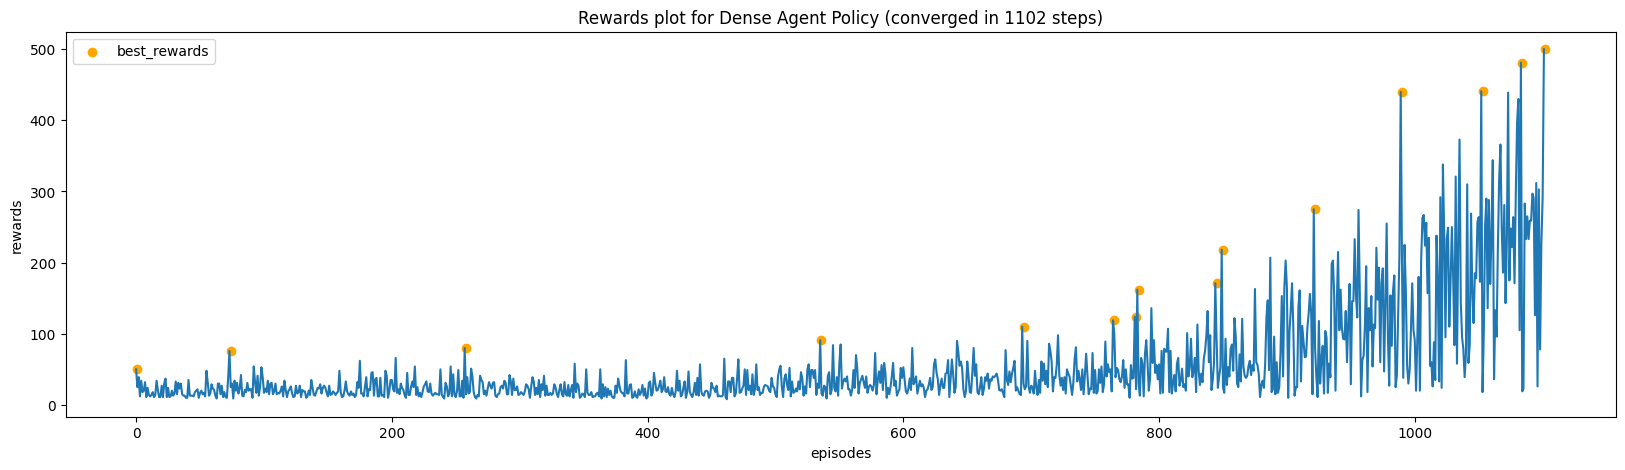

Evaluation reward of policy: 500.0
Average policy entropy of policy: 0.4832137
Pole angle variance of policy: 6.73e-05 rads


(500.0, 0.4832136731445789, 6.73293814313575e-05)

In [12]:
dense_policy_agent = PolicyNet(observation_space, action_space, hidden_size).to(os.getenv("DEVICE"))
dense_policy_agent.apply(xavier_init_weights)
dense_policy_target = copy.deepcopy(dense_policy_agent).to(os.getenv("DEVICE"))
dense_optimizer = torch.optim.Adam(dense_policy_agent.parameters(), lr=lr)
weights_filename = "CartPolev1_DQN_dense_agent.pth.tar"

run_train(
    dense_policy_agent, 
    dense_policy_target, 
    dense_optimizer, 
    weights_filename, 
    plot_performance=True
)

run_evaluation(dense_policy_agent, verbose=True)

## Train and Evaluate Sparse Policy Against Different Sparsity Coefficents

Training sparse policy with sparsity coef: 1e-05



 61%|██████    | 1215/2000 [05:45<03:43,  3.51it/s]


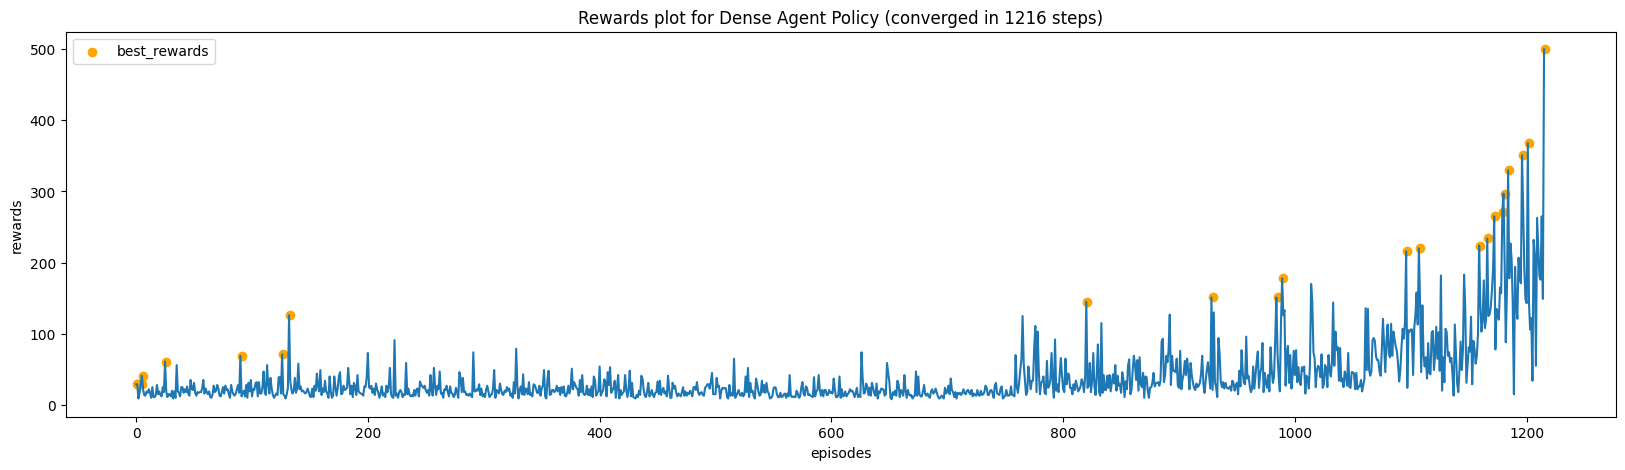

Training sparse policy with sparsity coef: 5e-05



 99%|█████████▉| 1976/2000 [06:29<00:04,  5.08it/s]


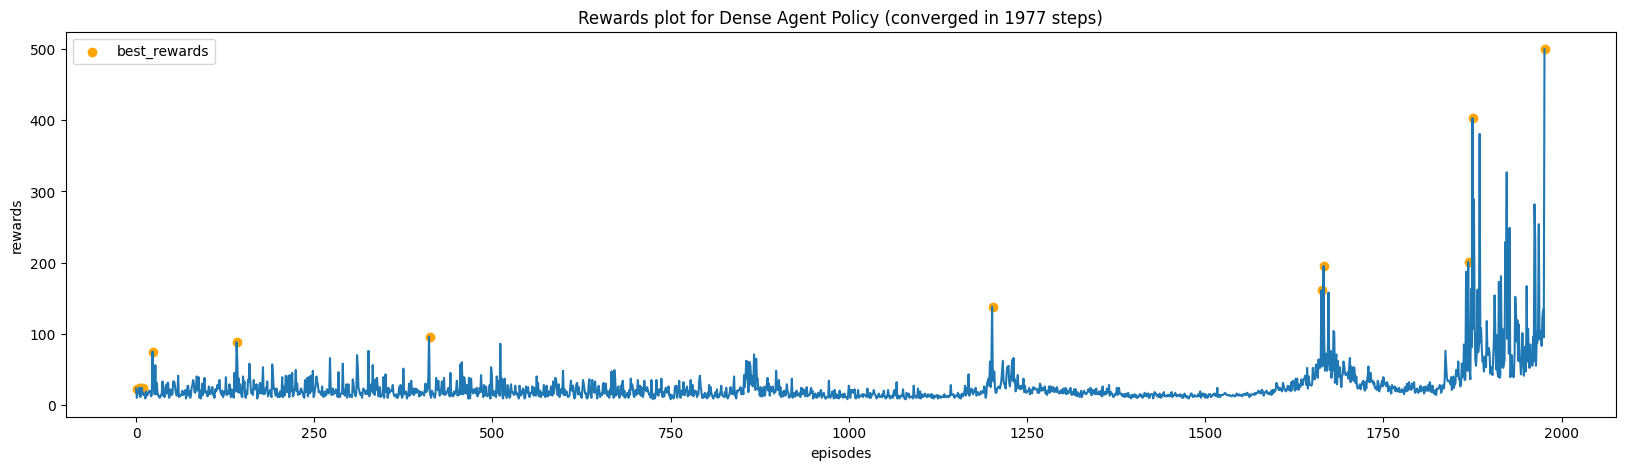

Training sparse policy with sparsity coef: 0.0001



100%|██████████| 2000/2000 [05:05<00:00,  6.54it/s]


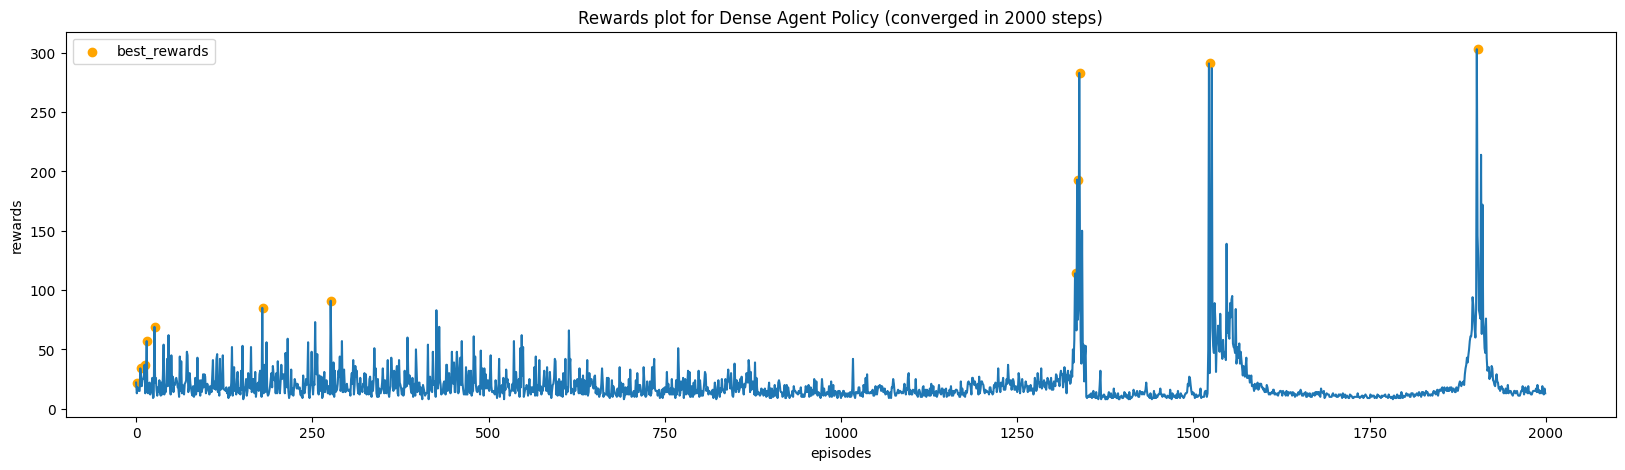

Training sparse policy with sparsity coef: 0.0005



 89%|████████▊ | 1774/2000 [06:26<00:49,  4.59it/s]


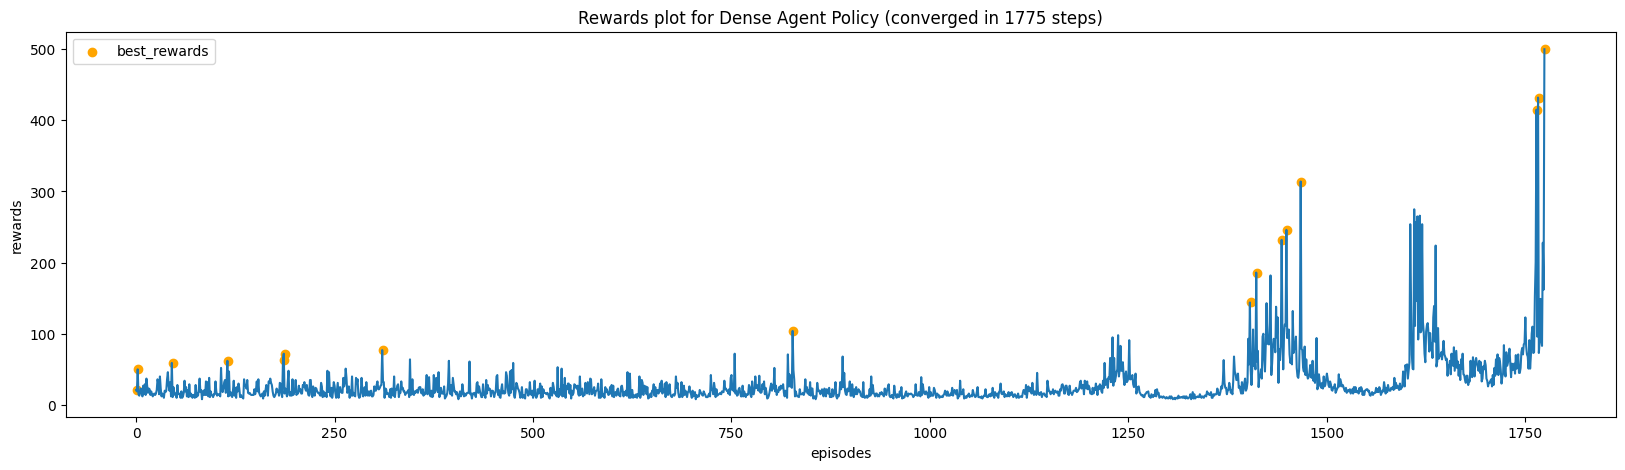

Training sparse policy with sparsity coef: 0.001



 94%|█████████▍| 1883/2000 [07:06<00:26,  4.42it/s]


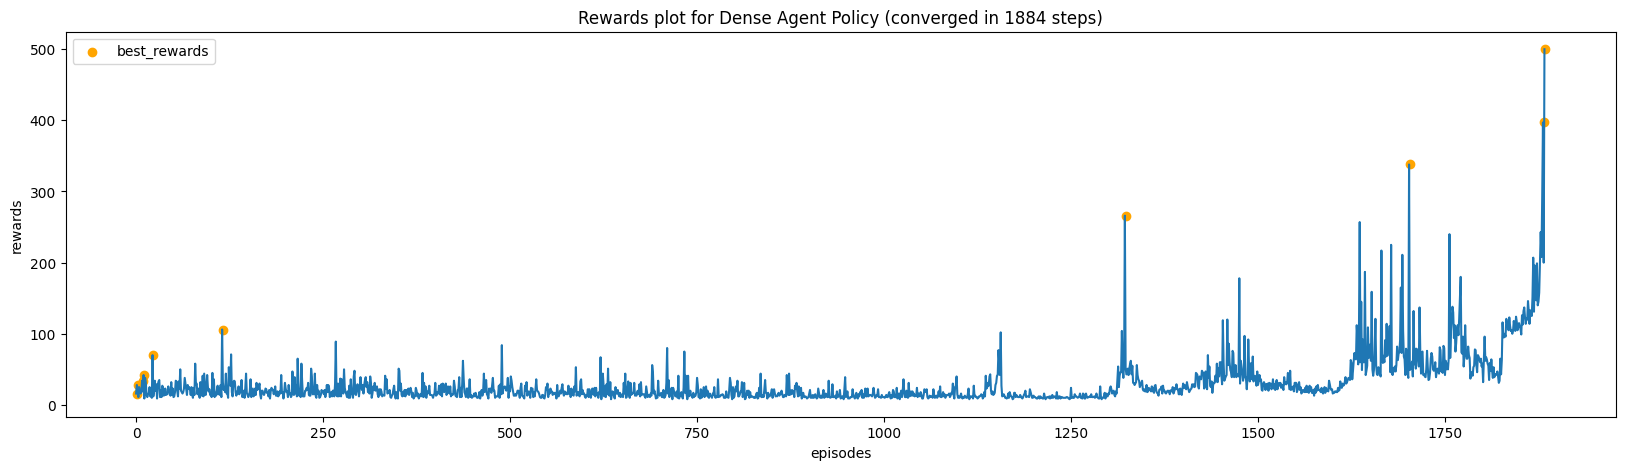

Training sparse policy with sparsity coef: 0.005



 84%|████████▍ | 1685/2000 [06:03<01:07,  4.64it/s]


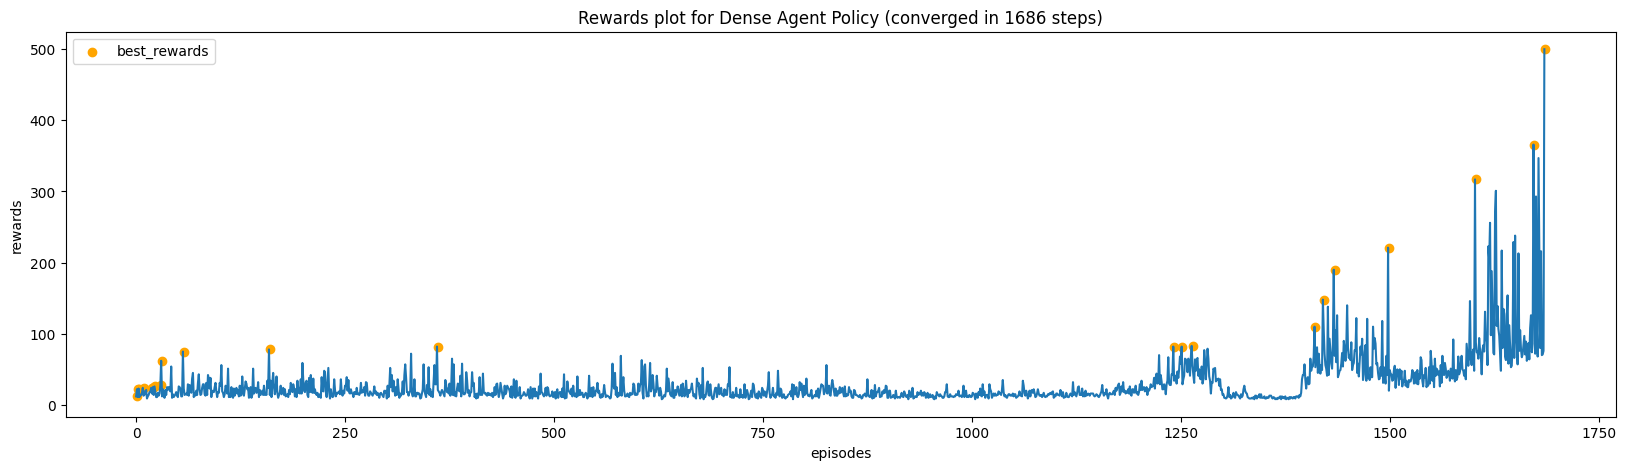

Training sparse policy with sparsity coef: 0.01



 80%|███████▉  | 1594/2000 [05:37<01:25,  4.73it/s]


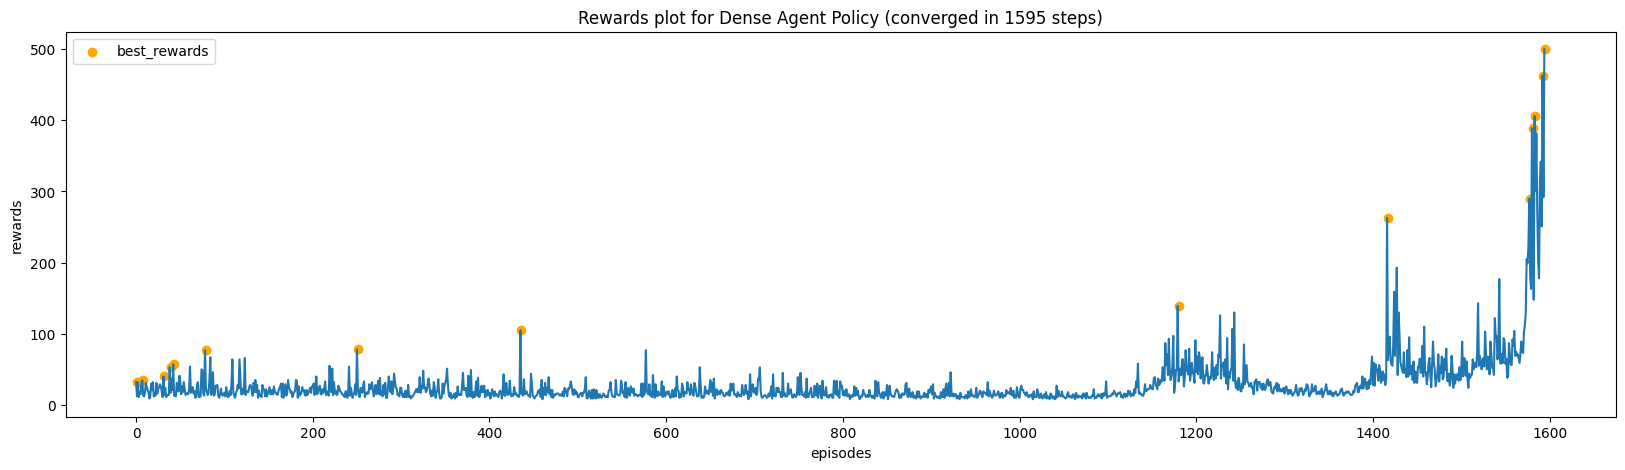

Training sparse policy with sparsity coef: 0.05



 74%|███████▍  | 1488/2000 [08:07<02:47,  3.05it/s]


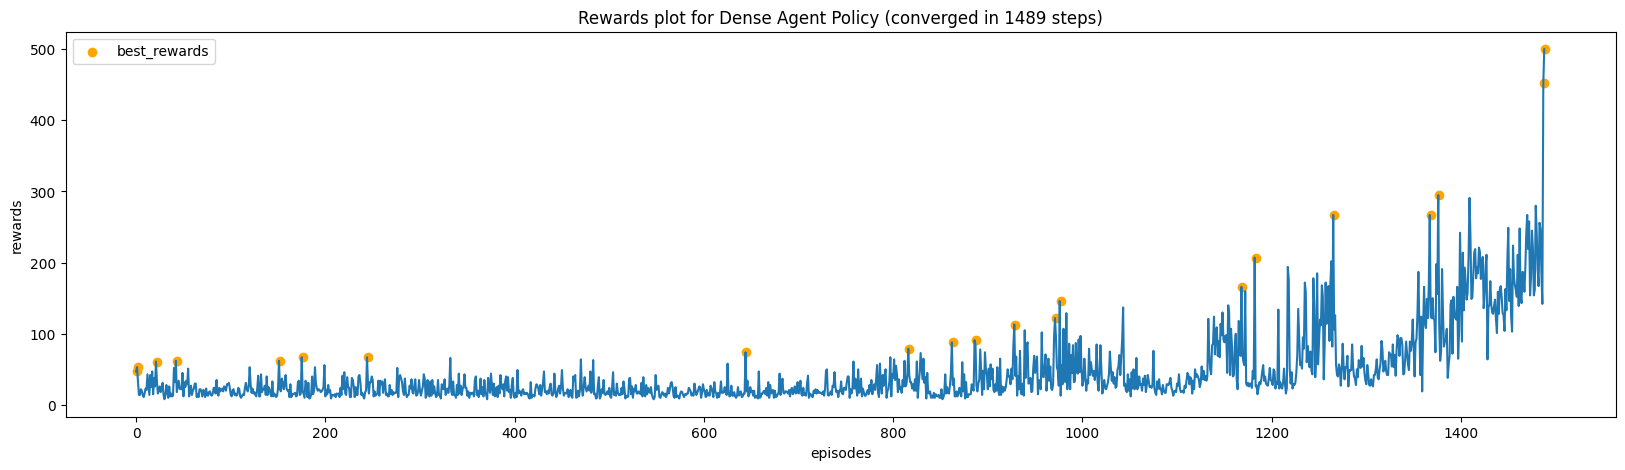

Training sparse policy with sparsity coef: 0.1



 73%|███████▎  | 1458/2000 [05:06<01:53,  4.76it/s]


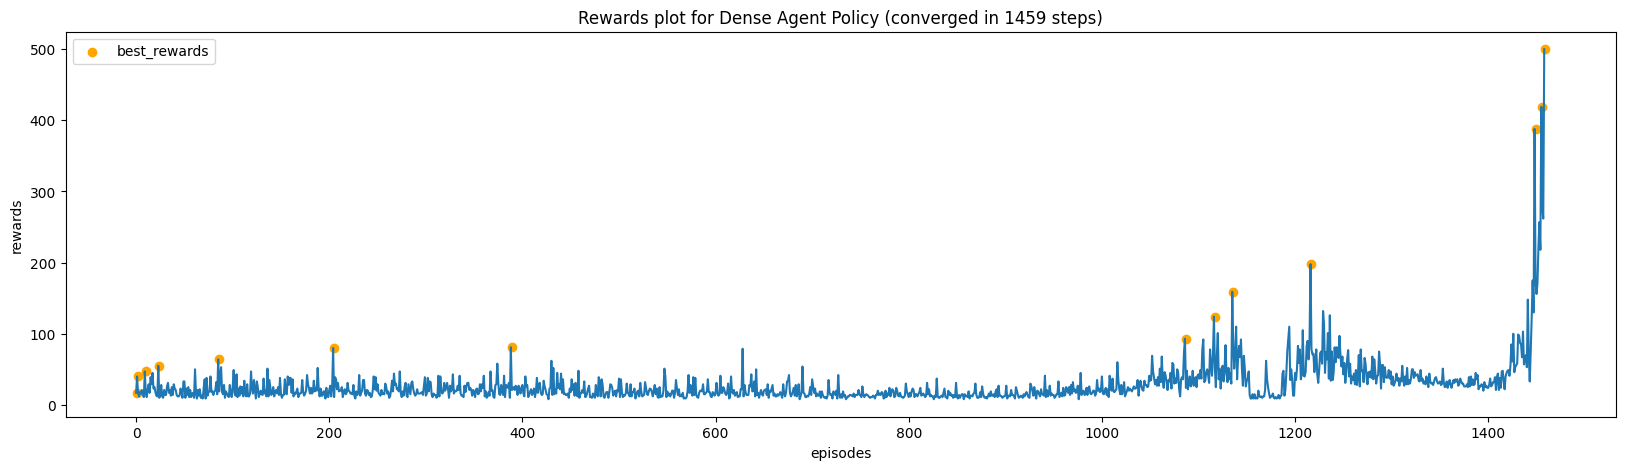

Training sparse policy with sparsity coef: 0.5



 66%|██████▌   | 1319/2000 [06:46<03:30,  3.24it/s]


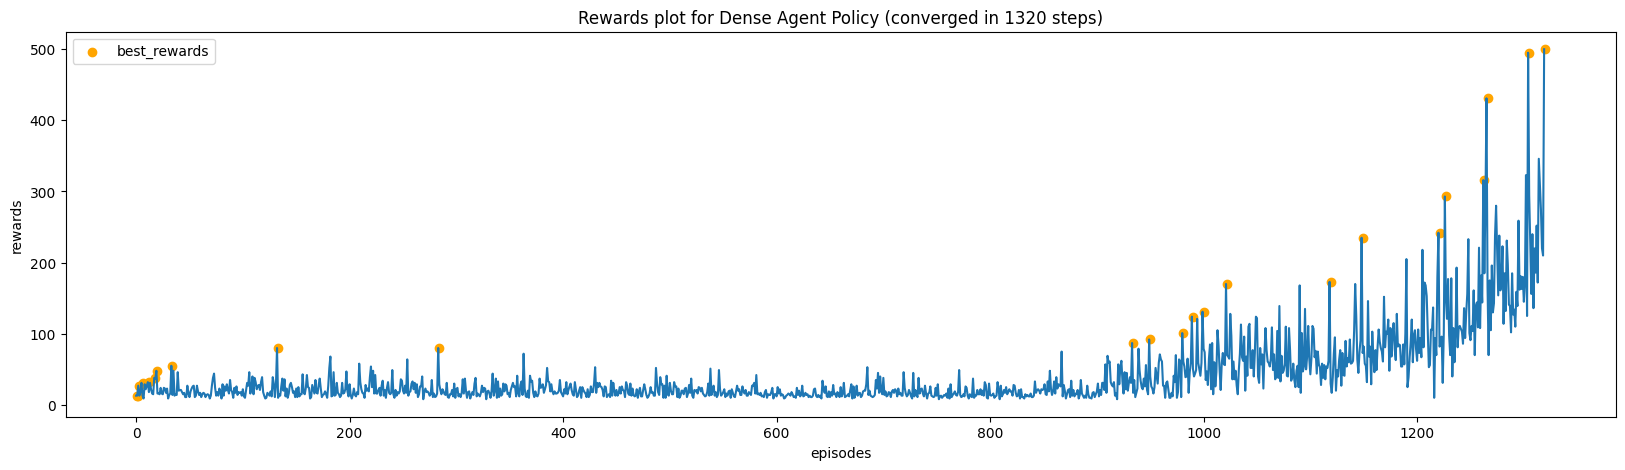

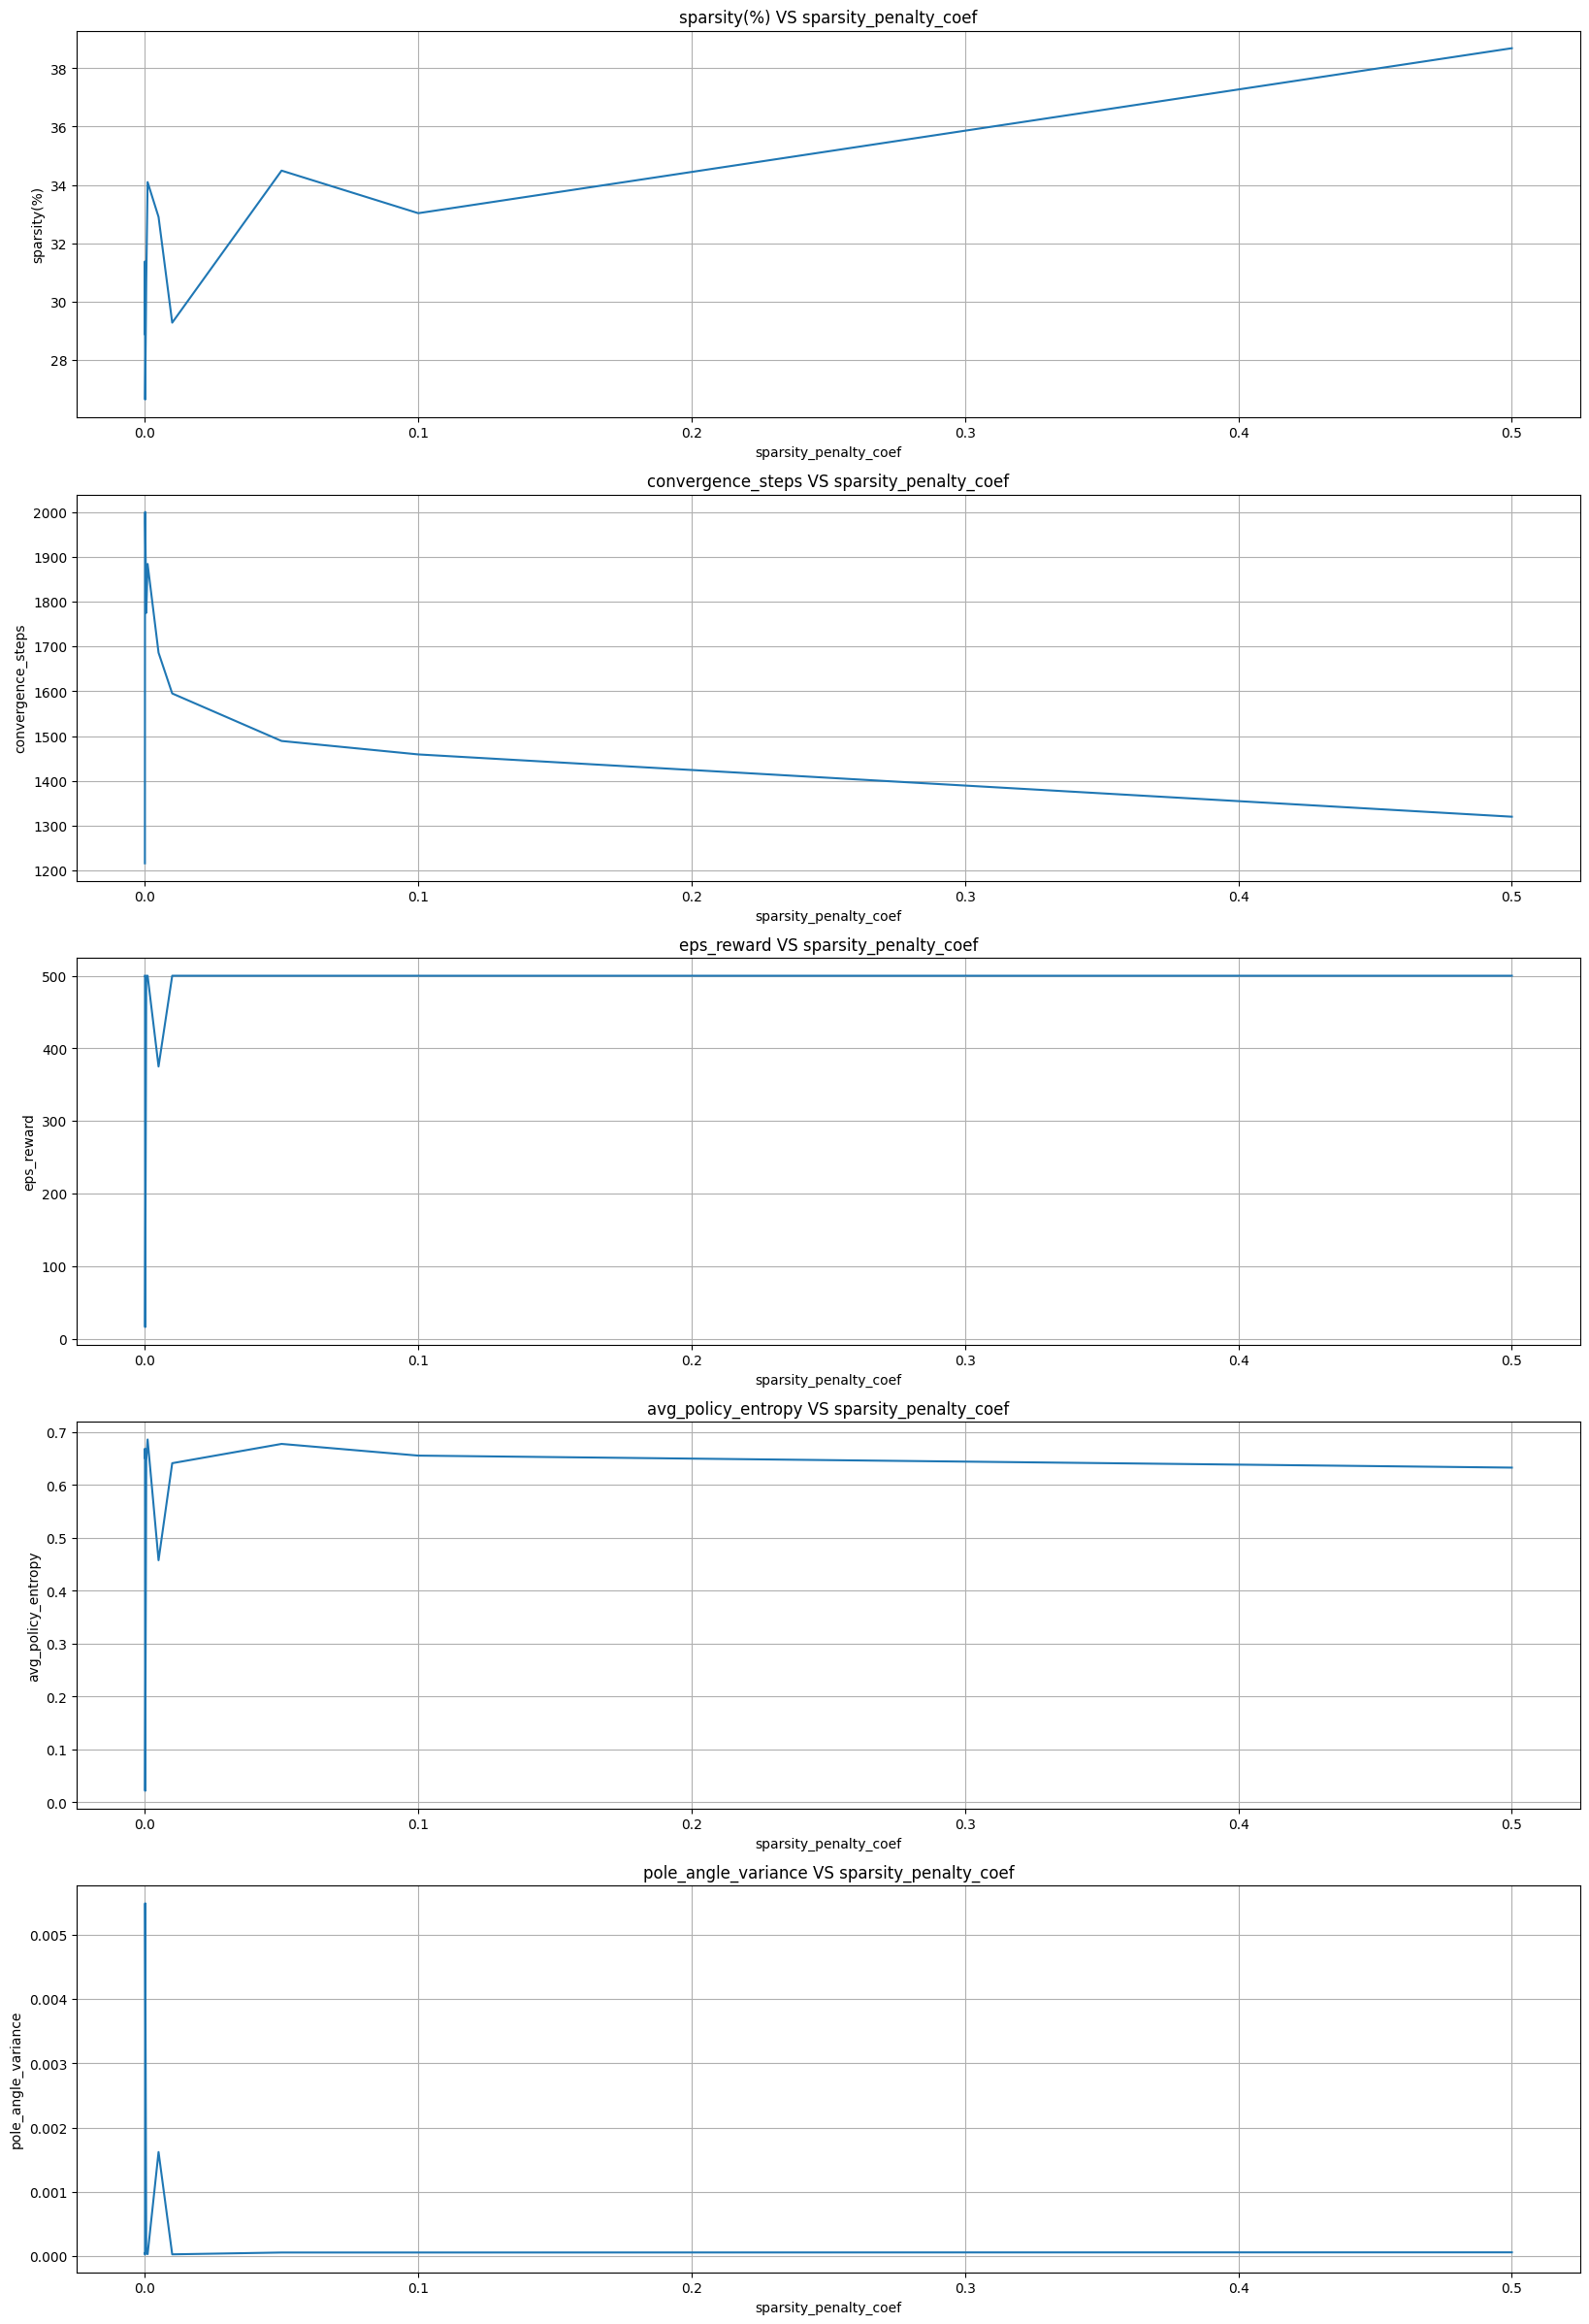

,sparsity_penalty_coef,sparsity(%),convergence_steps,eps_reward,avg_policy_entropy,pole_angle_variance
0,0.00001,28.890991,1216,500.0,0.651102,0.000046
1,0.00005,31.381226,1977,500.0,0.668542,0.000022
2,0.00010,26.647949,2000,16.0,0.021853,0.005491
3,0.00050,30.697632,1775,500.0,0.645301,0.000052
4,0.00100,34.097290,1884,500.0,0.685787,0.000028
5,0.00500,32.904053,1686,375.0,0.457649,0.001618
6,0.01000,29.281616,1595,500.0,0.641021,0.000026
7,0.05000,34.490967,1489,500.0,0.677457,0.000054
8,0.10000,33.032227,1459,500.0,0.655346,0.000054
9,0.50000,38.684082,1320,500.0,0.632654,0.000057


In [13]:
result = dict()
result["sparsity_penalty_coef"] = []
result["sparsity(%)"] = []
result["convergence_steps"] = []
result["eps_reward"] = []
result["avg_policy_entropy"] = []
result["pole_angle_variance"] = []

weights_filename = "CartPolev1_DQN_sparse_agent.pth.tar"
best_score = -np.inf

for coef in sparsity_penalty_coefs:
    sparse_policy_agent = SparsePolicyNet(
        observation_space, 
        action_space, 
        hidden_size, 
        sparsity_on_eval=True).to(os.getenv("DEVICE"))
    sparse_policy_agent.apply(xavier_init_weights)

    sparse_policy_target = SparsePolicyNet(
        observation_space, 
        action_space, 
        hidden_size, 
        sparsity_on_eval=True).to(os.getenv("DEVICE"))
    sparse_policy_target.load_state_dict(sparse_policy_agent.state_dict())

    sparse_optimizer = torch.optim.Adam(sparse_policy_agent.parameters(), lr=lr)

    print(f"Training sparse policy with sparsity coef: {coef}\n")

    convergence_steps = run_train(
        sparse_policy_agent, 
        sparse_policy_target, 
        sparse_optimizer, 
        save_best_weights=False, 
        sparse_penalty_coef=coef,
        plot_performance=True
    )
    eps_reward, avg_policy_entropy, pole_angle_variance = run_evaluation(sparse_policy_agent, verbose=False)
    weight_sparsity = sparse_policy_agent.compute_weight_sparsity()[1] * 100
    score = eps_reward + (weight_sparsity)

    if score > best_score:
        best_score = score
        save_model_params(sparse_policy_agent.state_dict(), weights_filename)

    result["sparsity_penalty_coef"].append(coef)
    result["sparsity(%)"].append(weight_sparsity)
    result["convergence_steps"].append(convergence_steps)
    result["eps_reward"].append(eps_reward)
    result["avg_policy_entropy"].append(avg_policy_entropy)
    result["pole_angle_variance"].append(pole_angle_variance)

    del sparse_policy_agent, sparse_policy_target, sparse_optimizer
    gc.collect()
    torch.cuda.empty_cache()

result = pd.DataFrame(result)
plot_result_dataframe(result, x_axis="sparsity_penalty_coef", figsize=(20, 30))
os.makedirs(results_dir, exist_ok=True)
result.to_csv(os.path.join(results_dir, "DQN_sparsification_results.csv"), index=False)
result